
[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Shape: (155744, 19)


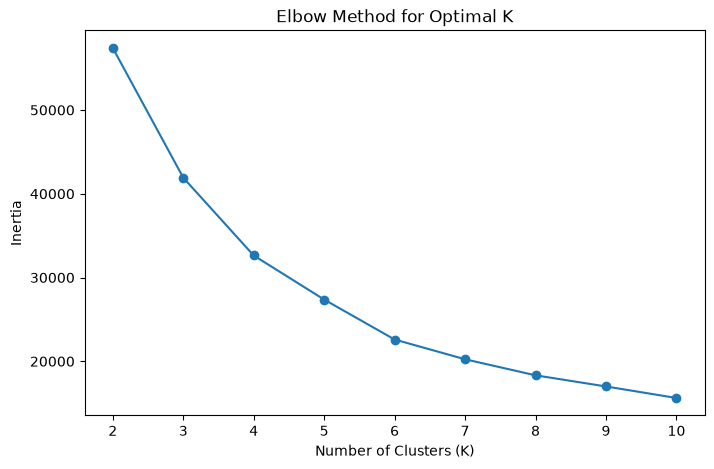


K-Means cluster sizes:
KMeans_Cluster
0    33801
1    34513
2    25536
3    26759
4    35135
Name: count, dtype: int64

K-Means Silhouette Score: 0.340

DBSCAN found 10 clusters and 674 noise points (out of 20000 sample rows)
DBSCAN Silhouette Score: 0.139

--- Comparison ---
K-Means Silhouette: 0.340
DBSCAN Silhouette:  0.139

Map saved to app/frontend/kmeans_clusters_map.html
Heatmap saved to app/frontend/accident_heatmap.html


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore



Saved clustered data to data/processed/accidents_with_clusters.csv
Saved K-Means model and scaler


In [7]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
%pip install folium
import folium
from folium.plugins import HeatMap


df = pd.read_csv('../data/processed/accidents_cleaned.csv')
print("Shape:", df.shape)


cluster_features = ['Start_Lat', 'Start_Lng', 'Hour', 'Temperature(F)', 'Visibility(mi)']
X_cluster = df[cluster_features].copy()


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)


sample_idx = np.random.RandomState(42).choice(len(X_scaled), size=20000, replace=False)
X_sample = X_scaled[sample_idx]

inertias = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_sample)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertias, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(list(k_range))
plt.show()


optimal_k = 5  
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("\nK-Means cluster sizes:")
print(df['KMeans_Cluster'].value_counts().sort_index())


kmeans_silhouette = silhouette_score(X_sample, KMeans(n_clusters=optimal_k, random_state=42, n_init=10).fit_predict(X_sample))
print(f"\nK-Means Silhouette Score: {kmeans_silhouette:.3f}")


dbscan = DBSCAN(eps=0.3, min_samples=15)
dbscan_sample_labels = dbscan.fit_predict(X_sample)

n_clusters_dbscan = len(set(dbscan_sample_labels)) - (1 if -1 in dbscan_sample_labels else 0)
n_noise = list(dbscan_sample_labels).count(-1)
print(f"\nDBSCAN found {n_clusters_dbscan} clusters and {n_noise} noise points (out of {len(X_sample)} sample rows)")

if n_clusters_dbscan > 1:
    dbscan_silhouette = silhouette_score(X_sample, dbscan_sample_labels)
    print(f"DBSCAN Silhouette Score: {dbscan_silhouette:.3f}")
else:
    print("DBSCAN found too few clusters — try adjusting eps (increase) or min_samples (decrease)")


print("\n--- Comparison ---")
print(f"K-Means Silhouette: {kmeans_silhouette:.3f}")
if n_clusters_dbscan > 1:
    print(f"DBSCAN Silhouette:  {dbscan_silhouette:.3f}")


map_sample = df.sample(n=5000, random_state=42)

m = folium.Map(location=[39.8, -98.5], zoom_start=4, tiles='OpenStreetMap')

colors = ['red', 'blue', 'green', 'purple', 'orange', 'darkred', 'cadetblue', 'black']
for _, row in map_sample.iterrows():
    folium.CircleMarker(
        location=[row['Start_Lat'], row['Start_Lng']],
        radius=2,
        color=colors[int(row['KMeans_Cluster']) % len(colors)],
        fill=True,
        fill_opacity=0.6
    ).add_to(m)

m.save('../app/frontend/kmeans_clusters_map.html')
print("\nMap saved to app/frontend/kmeans_clusters_map.html")
m


heat_data = map_sample[['Start_Lat', 'Start_Lng']].values.tolist()
m2 = folium.Map(location=[39.8, -98.5], zoom_start=4, tiles='CartoDB positron')
HeatMap(heat_data, radius=8).add_to(m2)
m2.save('../app/frontend/accident_heatmap.html')
print("Heatmap saved to app/frontend/accident_heatmap.html")


df.to_csv('../data/processed/accidents_with_clusters.csv', index=False)
print("\nSaved clustered data to data/processed/accidents_with_clusters.csv")

import joblib
joblib.dump(kmeans, '../app/models/kmeans_model.pkl')
joblib.dump(scaler, '../app/models/cluster_scaler.pkl')
print("Saved K-Means model and scaler")

In [8]:
from IPython.display import IFrame, display

display(IFrame(src="../app/frontend/kmeans_clusters_map.html", width=1000, height=600))
display(IFrame(src="../app/frontend/accident_heatmap.html", width=1000, height=600))
display(IFrame(src="../app/frontend/kmeans_clusters_map.html", width=1000, height=600))
display(IFrame(src="../app/frontend/accident_heatmap.html", width=1000, height=600))